# Practical Session â€” ResNet, Image Classification and Transfer Learning

## Context and objectives

Modern deep learning workflows increasingly rely on pretrained models and AI-assisted programming tools. However, being able to generate or execute code is not sufficient: engineers must understand the underlying mechanisms, assess implementation choices, and identify potential limitations.

In this practical session, you will work with code generated by an AI assistant to explore image classification using convolutional neural networks and the Hugging Face ecosystem. Your task is not simply to run the code, but to **read it critically, understand its logic, and connect its implementation to the theoretical concepts studied in class**.

The session is organized into two parts.

### Part 1 â€” Using a pretrained ResNet model

You will first discover how to use Hugging Face to load a pretrained ResNet model and apply it to an image classification task. You will investigate the main components of the inference pipeline, including image preprocessing, model inputs and outputs, class predictions...

You will also examine the architecture of ResNet by inspecting the intermediate representations produced by its different stages. This will help you understand how spatial resolution and the number of feature channels evolve throughout a convolutional neural network.

### Part 2 â€” Transfer learning for a new classification task

You will then adapt a pretrained ResNet model to a new image classification task. Starting from representations learned on a large dataset, you will investigate how a model can be reused and fine-tuned for a different prediction problem.

You will examine the modifications required to the classification head, the role of the training and validation datasets, the loss function, and the optimization procedure. You will also analyze the impact of different transfer learning strategies, such as training only the classification head or fine-tuning some or all of the network parameters.

## Expected outcomes

By the end of this session, you should be able to:

- Use Hugging Face to load, preprocess inputs for, and run inference with a pretrained model.
- Explain the principles of transfer learning and implement a basic fine-tuning procedure.
- Improve your skills to critically assess AI-generated code, including its assumptions, correctness, and potential limitations.

**Throughout the session, you are expected to justify the main implementation choices and explain what the code actually does, rather than merely demonstrating that it executes successfully.**

## Part 1 â€” Using a pretrained ResNet model

In [2]:
import random, time, io
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image

SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device = torch.device("mps" if torch.mps.is_available() else "cpu")
print("device:", device, "| torch", torch.__version__)
if device.type == "cpu":
    print("âš ï¸  No GPU detected: Some parts will be slow. Reduce epochs or use a GPU runtime.")

device: mps | torch 2.14.0


The Hugging Face Hub hosts pretrained checkpoints with their model card (training data, input size, license, intended use).

The high-level pipeline API hides everything: preprocessing â†’ forward pass â†’ postprocessing.

Before running: open the model card of [`microsoft/resnet-50`](https://huggingface.co/microsoft/resnet-50). Which dataset was it trained on? What input resolution does it expect?

Dataset: The dataset used to train ResNet50 was ImageNet 1K

Input resolution: The input resolution the model expects is 224x224

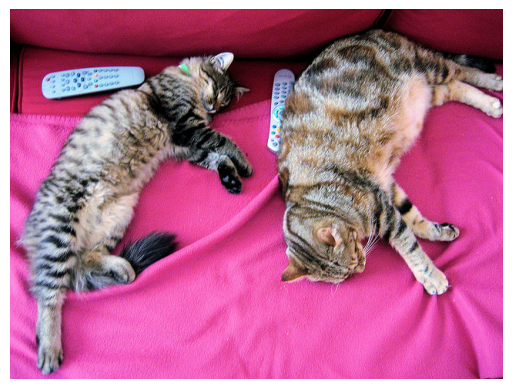

Loading weights: 100%|██████████| 320/320 [00:00<00:00, 16614.81it/s]


tiger cat                                0.941
tabby, tabby cat                         0.035
remote control, remote                   0.002
Egyptian cat                             0.001
jinrikisha, ricksha, rickshaw            0.001


In [ ]:
import requests
from transformers import pipeline

def load_image_from_url(url):
    r = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}, timeout=20)
    r.raise_for_status()
    return Image.open(io.BytesIO(r.content)).convert("RGB")

try:
    img = load_image_from_url("http://images.cocodataset.org/val2017/000000039769.jpg")
except Exception as e:
    print("URL failed, falling back to the cats-image dataset:", e)
    from datasets import load_dataset
    img = load_dataset("huggingface/cats-image", split="test")[0]["image"].convert("RGB")

plt.imshow(img); plt.axis("off"); plt.show()

classifier = pipeline("image-classification", model="microsoft/resnet-50",
                      device=0 if device.type == "mps" else -1)
for p in classifier(img, top_k=5):
    print(f"{p['label']:<40s} {p['score']:.3f}")

**Exercise 1.1**

1. Gather **3 images of your own** (upload files in Colab or use `load_image_from_url`): at least one *easy* (a clear dog/car/â€¦), one *ambiguous*, one with **no ImageNet class at all** (a face, a diagram, a screenshotâ€¦).
2. For each of the three models below, build a `pipeline`, measure the inference time, and print the top-3 predictions per image.

In [9]:
def load_image_from_url_agent(url):
    headers = {"User-Agent": "Mozilla/5.0"}
    response = requests.get(url, headers=headers, timeout=15)
    response.raise_for_status()

    return Image.open(io.BytesIO(response.content)).convert("RGB")

# URLs hosteds in GitHub
urls = {
    # Easy: Clear dog (well-defined class in ImageNet)
    "easy": "https://raw.githubusercontent.com/pytorch/hub/master/images/dog.jpg",
    # Ambiguous: Dog, bicycle and car in the same scene (multiple elements competing for attention)
    "ambiguous": "https://raw.githubusercontent.com/pjreddie/darknet/master/data/dog.jpg",
    # No ImageNet: digital logo/vector of Python (there is no class for logos/2D diagrams in ImageNet)
    "no_imagenet": "https://raw.githubusercontent.com/github/explore/80688e429a7d4ef2fca1e82350fe8e3517d3494d/topics/python/python.png"
}

images = {}
for category, url in urls.items():
    try:
        images[category] = load_image_from_url_agent(url)
        print(f"Image '{category}' successfully loaded!")
    except Exception as e:
        print(f"Error '{category}': {e}")

for category, img in images.items():
    print(f"\n--- Categoria: {category.upper()} ---")

    start_time = time.time()
    predictions = classifier(img, top_k=3)
    elapsed_time = time.time() - start_time

    print(f"Inference time: {elapsed_time:.4f}s")
    print("Top-3 Predictions:")
    for pred in predictions:
        print(f"  - {pred['label']:<35s} (Score: {pred['score']:.4f})")

Image 'easy' successfully loaded!
Image 'ambiguous' successfully loaded!
Image 'no_imagenet' successfully loaded!

--- Categoria: EASY ---
Inference time: 0.0217s
Top-3 Predictions:
  - Samoyed, Samoyede                   (Score: 0.9727)
  - Pomeranian                          (Score: 0.0060)
  - keeshond                            (Score: 0.0036)

--- Categoria: AMBIGUOUS ---
Inference time: 0.0102s
Top-3 Predictions:
  - malamute, malemute, Alaskan malamute (Score: 0.9860)
  - bicycle-built-for-two, tandem bicycle, tandem (Score: 0.0037)
  - mountain bike, all-terrain bike, off-roader (Score: 0.0008)

--- Categoria: NO_IMAGENET ---
Inference time: 0.0095s
Top-3 Predictions:
  - hook, claw                          (Score: 0.2138)
  - spatula                             (Score: 0.2040)
  - paper towel                         (Score: 0.0984)


**Under the hood**

`pipeline` is convenient, but for research and fine-tuning you need the two building blocks:

- `AutoImageProcessor`: resize / crop / rescale / normalise â†’ `pixel_values`
- `AutoModelForImageClassification`: backbone + classification head â†’ **logits** (not probabilities)

In [10]:
from transformers import AutoImageProcessor, AutoModelForImageClassification

ckpt = "microsoft/resnet-50"
processor = AutoImageProcessor.from_pretrained(ckpt)
model = AutoModelForImageClassification.from_pretrained(ckpt).to(device).eval()

print(processor)
print("number of classes:", len(model.config.id2label))

Loading weights: 100%|██████████| 320/320 [00:00<00:00, 17166.47it/s]

ConvNextImageProcessor {
  "crop_pct": 0.875,
  "do_normalize": true,
  "do_rescale": true,
  "do_resize": true,
  "image_mean": [
    0.485,
    0.456,
    0.406
  ],
  "image_processor_type": "ConvNextImageProcessor",
  "image_std": [
    0.229,
    0.224,
    0.225
  ],
  "resample": 3,
  "rescale_factor": 0.00392156862745098,
  "size": {
    "shortest_edge": 224
  }
}

number of classes: 1000


In [11]:
inputs = processor(images=img, return_tensors="pt").to(device)
print("pixel_values:", tuple(inputs["pixel_values"].shape), inputs["pixel_values"].dtype)

with torch.no_grad():
    out = model(**inputs)
logits = out.logits
probs = logits.softmax(-1)[0]
top = probs.topk(5)
for p, i in zip(top.values, top.indices):
    print(f"{model.config.id2label[i.item()]:<40s} {p.item():.3f}")

pixel_values: (1, 3, 224, 224) torch.float32
hook, claw                               0.214
spatula                                  0.204
paper towel                              0.098
cleaver, meat cleaver, chopper           0.079
envelope                                 0.030


Have a look to the model structure

In [12]:
model

ResNetForImageClassification(
  (resnet): ResNetModel(
    (embedder): ResNetEmbeddings(
      (embedder): ResNetConvLayer(
        (convolution): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
        (normalization): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (activation): ReLU()
      )
      (pooler): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    )
    (encoder): ResNetEncoder(
      (stages): ModuleList(
        (0): ResNetStage(
          (layers): Sequential(
            (0): ResNetBottleNeckLayer(
              (shortcut): ResNetShortCut(
                (convolution): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
                (normalization): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
              )
              (layer): Sequential(
                (0): ResNetConvLayer(
                  (c

Let's look at the feature hierarchy.
With output_hidden_states=True, a transformers ResNet returns the output of the embedder (stem) and of each of the 4 stages.

In [13]:
with torch.no_grad():
    out = model(**inputs, output_hidden_states=True)
for i, h in enumerate(out.hidden_states):
    print(f"hidden_states[{i}]: {tuple(h.shape)}")

hidden_states[0]: (1, 64, 56, 56)
hidden_states[1]: (1, 256, 56, 56)
hidden_states[2]: (1, 512, 28, 28)
hidden_states[3]: (1, 1024, 14, 14)
hidden_states[4]: (1, 2048, 7, 7)


In [14]:
def n_params(m):
    return sum(p.numel() for p in m.parameters())

blocks = {"embedder": model.resnet.embedder,
          **{f"stage{i}": s for i, s in enumerate(model.resnet.encoder.stages)},
          "classifier": model.classifier}
total = n_params(model)
print(f"total: {total/1e6:.2f} M parameters")
for k, m in blocks.items():
    print(f"{k:<11s} {n_params(m)/1e6:6.2f} M  ({100*n_params(m)/total:4.1f} %)")

total: 25.56 M parameters
embedder      0.01 M  ( 0.0 %)
stage0        0.22 M  ( 0.8 %)
stage1        1.22 M  ( 4.8 %)
stage2        7.10 M  (27.8 %)
stage3       14.96 M  (58.6 %)
classifier    2.05 M  ( 8.0 %)


idx 0 | res 56x56 | channels   64 | stride 4
idx 1 | res 56x56 | channels  256 | stride 4
idx 2 | res 28x28 | channels  512 | stride 8
idx 3 | res 14x14 | channels 1024 | stride 16
idx 4 | res  7x7  | channels 2048 | stride 32


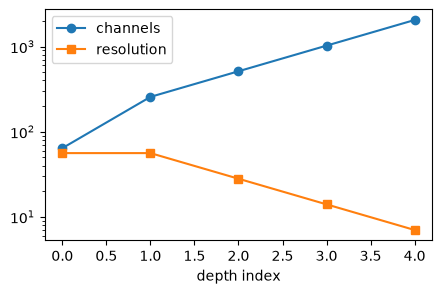

In [15]:
H = inputs["pixel_values"].shape[-1]
rows = []
for i, h in enumerate(out.hidden_states):
    rows.append((i, h.shape[-1], h.shape[1], H // h.shape[-1]))
for r in rows: print("idx %d | res %2dx%-2d | channels %4d | stride %d" % (r[0], r[1], r[1], r[2], r[3]))

fig, ax = plt.subplots(figsize=(5, 3))
ax.plot([r[0] for r in rows], [r[2] for r in rows], "o-", label="channels")
ax.plot([r[0] for r in rows], [r[1] for r in rows], "s-", label="resolution")
ax.set_yscale("log"); ax.set_xlabel("depth index"); ax.legend(); plt.show()

Expected: the (Embedder) stem divides resolution by 4; each stage then divides it by 2 (except the first) while channels grow Ã—2 (stage widths 256 â†’ 512 â†’ 1024 â†’ 2048 for ResNet-50).

Early layers detect local, generic patterns (edges, textures); deep layers respond to class-specific parts. Let's check on a real image.

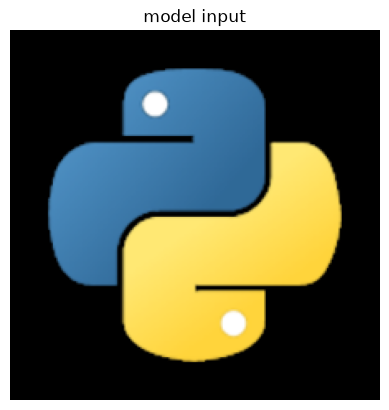

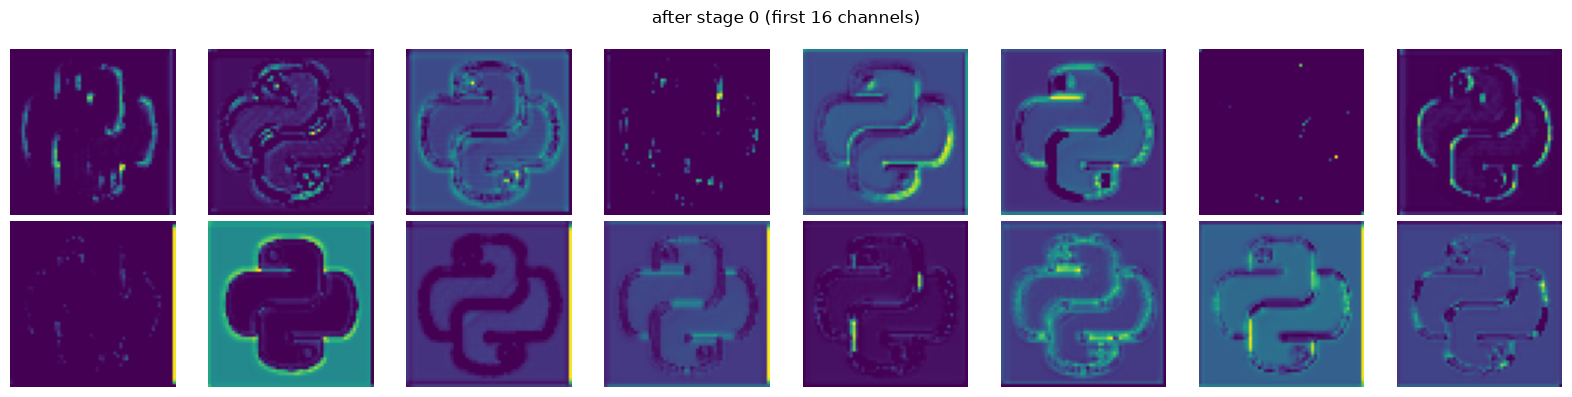

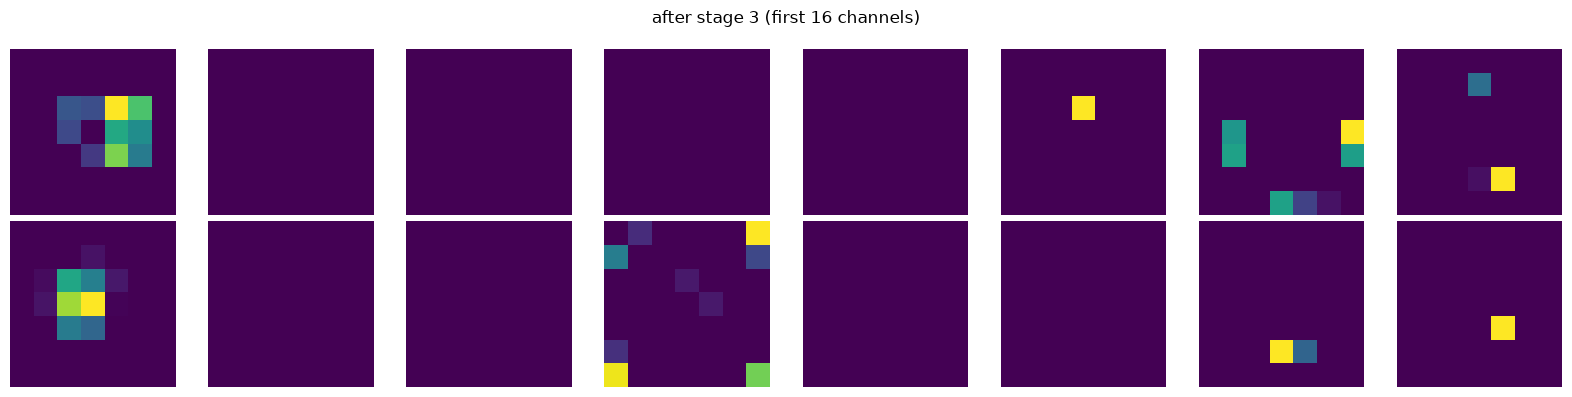

In [16]:
def denorm(pixel_values, processor):
    mean = torch.tensor(processor.image_mean).view(1, 3, 1, 1)
    std = torch.tensor(processor.image_std).view(1, 3, 1, 1)
    return (pixel_values.detach().cpu() * std + mean).clamp(0, 1)[0].permute(1, 2, 0).numpy()

def show_feature_maps(fmap, n=16, title=""):
    fmap = fmap[0].detach().cpu()
    cols = 8
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(2 * cols, 2 * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes: ax.axis("off")
    for k in range(n): axes[k].imshow(fmap[k], cmap="viridis")
    fig.suptitle(title); plt.tight_layout(); plt.show()

x_img = denorm(inputs["pixel_values"], processor)
plt.imshow(x_img); plt.axis("off"); plt.title("model input"); plt.show()
show_feature_maps(out.hidden_states[1], title="after stage 0 (first 16 channels)")
show_feature_maps(out.hidden_states[4], title="after stage 3 (first 16 channels)")

## Part 2 â€” Transfer learning for a new classification task

### Downloading dataset

**Task:** diagnose bean-leaf diseases from photos â€” [`AI-Lab-Makerere/beans`](https://huggingface.co/datasets/AI-Lab-Makerere/beans) (3 classes: *angular leaf spot*, *bean rust*, *healthy*; ~1k training images).

We will compare three regimes with the **same backbone** (`microsoft/resnet-18`):

| Regime | What is trained | Intuition |
|---|---|---|
| **Linear probing** | only the new linear head | "are ImageNet features already good enough?" |
| **Full fine-tuning** | everything, small LR | "adapt all features to the new domain" |
| **From scratch** | everything, random init | "what did pretraining actually buy us?" |

Generating test split: 100%|██████████| 128/128 [00:00<00:00, 14811.05 examples/s]


DatasetDict({
    train: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 1034
    })
    validation: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 133
    })
    test: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 128
    })
})
['angular_leaf_spot', 'bean_rust', 'healthy']


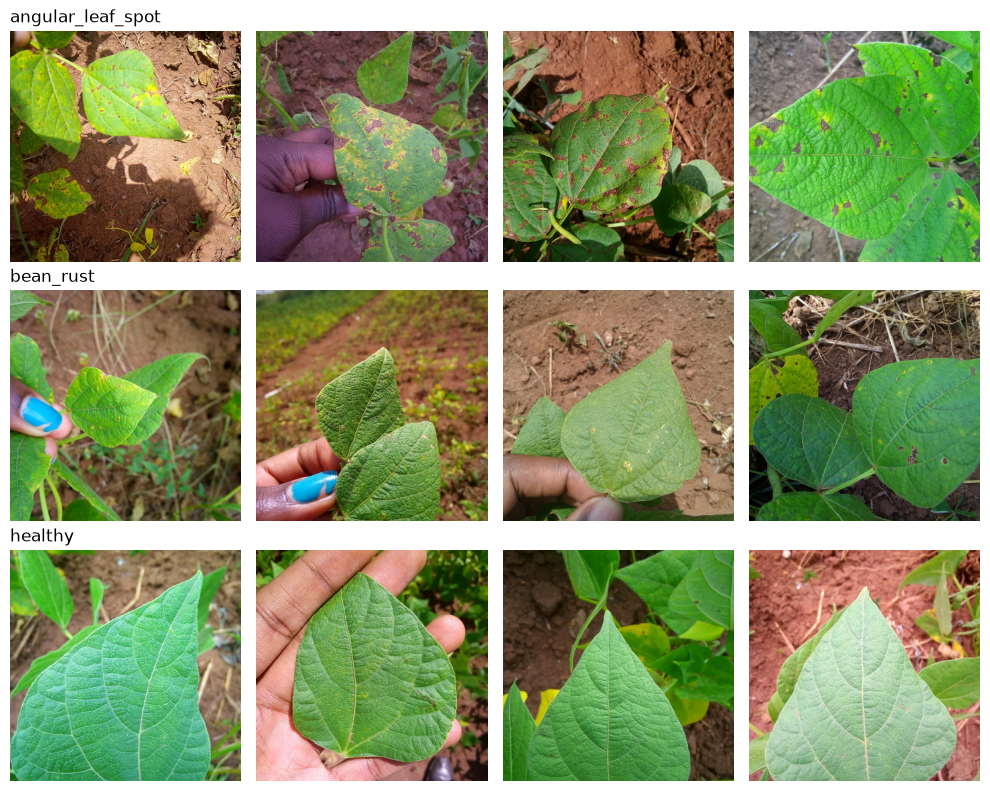

In [17]:
from datasets import load_dataset

ds = load_dataset("AI-Lab-Makerere/beans")
print(ds)
class_names = ds["train"].features["labels"].names
print(class_names)

labels_train = ds["train"]["labels"]
fig, axes = plt.subplots(3, 4, figsize=(10, 8))
for c, name in enumerate(class_names):
    idxs = [i for i, l in enumerate(labels_train) if l == c][:4]
    for j, i in enumerate(idxs):
        axes[c, j].imshow(ds["train"][i]["image"]); axes[c, j].axis("off")
    axes[c, 0].set_title(name, loc="left")
plt.tight_layout(); plt.show()

### Data pipeline

Two rules to keep in mind when using a pretrained backbone:
1. Use the **same normalisation** as pretraining (`processor.image_mean / image_std`).
2. Data augmentation only on the **training** split.

In [45]:
from torchvision import transforms as T
from torch.utils.data import DataLoader

CKPT = "microsoft/resnet-18"
BATCH = 32

def build_tf(processor, train):
    norm = T.Normalize(processor.image_mean, processor.image_std)
    if train:
        return T.Compose([T.RandomResizedCrop(224, scale=(0.6, 1.0)), T.RandomHorizontalFlip(),
                          T.ToTensor(), norm])
    return T.Compose([T.Resize(256), T.CenterCrop(224), T.ToTensor(), norm])

def collate(batch):
    return {"pixel_values": torch.stack([b["pixel_values"] for b in batch]),
            "labels": torch.tensor([b["labels"] for b in batch])}

def make_loader(split, processor, train):
    tf = build_tf(processor, train)
    def transform(batch):
        return {"pixel_values": [tf(im.convert("RGB")) for im in batch["image"]],
                "labels": batch["labels"]}
    return DataLoader(ds[split].with_transform(transform), batch_size=BATCH,
                      shuffle=train, num_workers=0, collate_fn=collate)

processor_r18 = AutoImageProcessor.from_pretrained(CKPT)
train_loader = make_loader("train", processor_r18, train=True)
val_loader = make_loader("validation", processor_r18, train=False)
test_loader = make_loader("test", processor_r18, train=False)
print(len(train_loader.dataset), len(val_loader.dataset), len(test_loader.dataset))

1034 133 128


Exercise:

1.   Implement the code to compare the different regimes with regard to accuracy.
2.   Evaluate how the best model degrades under distribution shift (apply Gaussian noise and Gaussian blur to the test set and track accuracy, e.g. functions defined below).





#### Noise functions

In [46]:
def gaussian_noise(s):
    return lambda x: (x + s * torch.randn_like(x)).clamp(0, 1)

def gaussian_blur(s):
    if s == 0: return lambda x: x
    k = 2 * int(np.ceil(3 * s)) + 1
    return lambda x: T.functional.gaussian_blur(x, kernel_size=k, sigma=s)

### Linear Probing

#### Freezing parameters function

In [47]:
def setup_linear_probing(model):
    # Freezes all the parameters of the model (backbone + classifier)
    for param in model.parameters():
        param.requires_grad = False

    # Unfreeze only the parameters of the final classifier
    for param in model.classifier.parameters():
        param.requires_grad = True


def inspect_requires_grad(model, label=""):
    print(f"\n=== Status de requires_grad: {label} ===")

    # Keywords that are compatible with Hugging Face's ResNet model structure
    target_keywords = ["embedder.embedder.convolution", "stages.0.layers.0.layer.0.convolution", "classifier"]

    for name, param in model.named_parameters():
        if any(k in name for k in target_keywords):
            print(f"{name:<60} -> requires_grad = {param.requires_grad}")

#### Setting device and loading the model

In [48]:
device = "mps"
id2label = {i: name for i, name in enumerate(class_names)}
label2id = {name: i for i, name in enumerate(class_names)}

model_name = "resnet_18_lin_prob"
resnet_18_lin_prob = AutoModelForImageClassification.from_pretrained(
    CKPT,
    num_labels=len(class_names),
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True
).to(device)

[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `1000`.
Loading weights: 100%|██████████| 122/122 [00:00<00:00, 13783.67it/s]
[transformers] ResNetForImageClassification LOAD REPORT from: microsoft/resnet-18
Key                 | Status   |                                                                                          
--------------------+----------+------------------------------------------------------------------------------------------
classifier.1.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([3])          
classifier.1.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 512]) vs model:torch.Size([3, 512])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


#### Freezing ResNet18 parameters

In [49]:
setup_linear_probing(resnet_18_lin_prob)
inspect_requires_grad(resnet_18_lin_prob, label="after freezing")


=== Status de requires_grad: after freezing ===
resnet.embedder.embedder.convolution.weight                  -> requires_grad = False
resnet.encoder.stages.0.layers.0.layer.0.convolution.weight  -> requires_grad = False
classifier.1.weight                                          -> requires_grad = True
classifier.1.bias                                            -> requires_grad = True


#### Training and Evaluation functions

In [50]:
def train_one_epoch(model, optimizer, data_loader, device):
    model.train()
    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    for batch in data_loader:
        images = batch["pixel_values"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad()
        output = model(pixel_values=images, labels=labels)
        loss = output.loss
        logits = output.logits
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(logits, 1)
        correct_predictions += torch.sum(preds == labels).item()
        total_samples += images.size(0)

    epoch_loss = running_loss / total_samples
    epoch_acc = correct_predictions / total_samples

    return epoch_loss, epoch_acc


@torch.no_grad()
def evaluate(model, data_loader, device):
    model.eval()
    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    for batch in data_loader:
        images = batch["pixel_values"].to(device)
        labels = batch["labels"].to(device)

        output = model(pixel_values=images, labels=labels)
        loss = output.loss
        logits = output.logits

        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(logits, 1)
        correct_predictions += torch.sum(preds == labels).item()
        total_samples += images.size(0)

    eval_loss = running_loss / total_samples
    eval_acc = correct_predictions / total_samples

    return eval_loss, eval_acc

#### Fitting the model

In [51]:
import os
import json

def fit(model, model_name, train_loader, val_loader, device, epochs, optimizer):
    best_val_acc = 0.0
    checkpoint_dir = f"checkpoints/beans_{model_name}"
    os.makedirs(checkpoint_dir, exist_ok=True)

    for epoch in range(epochs):
        train_loss, train_acc = train_one_epoch(model, optimizer, train_loader, device)
        val_loss, val_acc = evaluate(model, val_loader, device)

        print(f"Epoch {epoch + 1}/{epochs}: "
              f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}, "
              f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")

        if val_acc > best_val_acc:
            best_val_acc = val_acc

            # Saves the weights of the best model
            torch.save(model.state_dict(), f"{checkpoint_dir}/best_model.pth")

            # Save the metrics of the best model to a JSON file
            metrics = {
                "best_epoch": epoch + 1,
                "train_acc": round(train_acc, 4),
                "val_acc": round(val_acc, 4)
            }
            with open(f"{checkpoint_dir}/metrics.json", "w") as f:
                json.dump(metrics, f, indent=4)

            print("Best model saved with Val Acc:", best_val_acc)


optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, resnet_18_lin_prob.parameters()),
    lr=1e-3
)
epochs = 10

fit(resnet_18_lin_prob, model_name, train_loader, val_loader, device, epochs, optimizer)

Epoch 1/10: Train Loss: 0.8607, Train Acc: 0.6064, Val Loss: 0.5979, Val Acc: 0.8346
Best model saved with Val Acc: 0.8345864661654135
Epoch 2/10: Train Loss: 0.6005, Train Acc: 0.7766, Val Loss: 0.4481, Val Acc: 0.9023
Best model saved with Val Acc: 0.9022556390977443
Epoch 3/10: Train Loss: 0.5038, Train Acc: 0.8308, Val Loss: 0.3818, Val Acc: 0.8797
Epoch 4/10: Train Loss: 0.4584, Train Acc: 0.8395, Val Loss: 0.3256, Val Acc: 0.9248
Best model saved with Val Acc: 0.924812030075188
Epoch 5/10: Train Loss: 0.4124, Train Acc: 0.8549, Val Loss: 0.3241, Val Acc: 0.9173
Epoch 6/10: Train Loss: 0.3851, Train Acc: 0.8617, Val Loss: 0.2827, Val Acc: 0.9474
Best model saved with Val Acc: 0.9473684210526315
Epoch 7/10: Train Loss: 0.3555, Train Acc: 0.8839, Val Loss: 0.2748, Val Acc: 0.9323
Epoch 8/10: Train Loss: 0.3446, Train Acc: 0.8781, Val Loss: 0.2819, Val Acc: 0.9323
Epoch 9/10: Train Loss: 0.3276, Train Acc: 0.8956, Val Loss: 0.2685, Val Acc: 0.9248
Epoch 10/10: Train Loss: 0.3207, Tra

#### Evaluating the model in the test set

In [52]:
# Loads the best model weights
resnet_18_lin_prob.load_state_dict(torch.load(f"checkpoints/beans_{model_name}/best_model.pth"))

# Evaluates the model on the test_loader
test_loss, test_acc = evaluate(resnet_18_lin_prob, test_loader, device)
print(f"Test Loss: {test_loss:.4f} | Test Acc: {test_acc*100:.2f}%")

Test Loss: 0.3880 | Test Acc: 85.94%


### Full fine-tuning

#### Loading pre-trained ResNet18

In [53]:
model_name = "resnet_18_full_finet"

# Reloads the model with all layers trainable for full fine-tuning
resnet_18_full_finet = AutoModelForImageClassification.from_pretrained(
    CKPT,
    num_labels=len(class_names),
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True
).to(device)

[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `1000`.
Loading weights: 100%|██████████| 122/122 [00:00<00:00, 15374.83it/s]
[transformers] ResNetForImageClassification LOAD REPORT from: microsoft/resnet-18
Key                 | Status   |                                                                                          
--------------------+----------+------------------------------------------------------------------------------------------
classifier.1.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([3])          
classifier.1.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 512]) vs model:torch.Size([3, 512])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


#### Fitting the model

In [55]:
optimizer = torch.optim.AdamW(resnet_18_full_finet.parameters(), lr=1e-4)

fit(resnet_18_full_finet, model_name, train_loader, val_loader, device, epochs=10, optimizer=optimizer)

Epoch 1/10: Train Loss: 0.0662, Train Acc: 0.9739, Val Loss: 0.1003, Val Acc: 0.9699
Best model saved with Val Acc: 0.9699248120300752
Epoch 2/10: Train Loss: 0.0584, Train Acc: 0.9865, Val Loss: 0.0669, Val Acc: 0.9624
Epoch 3/10: Train Loss: 0.0531, Train Acc: 0.9826, Val Loss: 0.0644, Val Acc: 0.9850
Best model saved with Val Acc: 0.9849624060150376
Epoch 4/10: Train Loss: 0.0552, Train Acc: 0.9807, Val Loss: 0.0339, Val Acc: 0.9850
Epoch 5/10: Train Loss: 0.0225, Train Acc: 0.9942, Val Loss: 0.0851, Val Acc: 0.9699
Epoch 6/10: Train Loss: 0.0295, Train Acc: 0.9894, Val Loss: 0.0481, Val Acc: 0.9774
Epoch 7/10: Train Loss: 0.0205, Train Acc: 0.9923, Val Loss: 0.0465, Val Acc: 0.9850
Epoch 8/10: Train Loss: 0.0145, Train Acc: 0.9961, Val Loss: 0.0476, Val Acc: 0.9774
Epoch 9/10: Train Loss: 0.0124, Train Acc: 0.9961, Val Loss: 0.0285, Val Acc: 0.9850
Epoch 10/10: Train Loss: 0.0119, Train Acc: 0.9990, Val Loss: 0.0719, Val Acc: 0.9699


#### Evaluating the model in the test set

In [56]:
# Loads the best model weights
resnet_18_full_finet.load_state_dict(torch.load(f"checkpoints/beans_{model_name}/best_model.pth"))

# Evaluates the model on the test_loader
test_loss, test_acc = evaluate(resnet_18_full_finet, test_loader, device)
print(f"Test Loss: {test_loss:.4f} | Test Acc: {test_acc*100:.2f}%")

Test Loss: 0.0933 | Test Acc: 96.88%


### From scratch

#### Loading ResNet18 architecture 

In [59]:
from transformers import AutoConfig, AutoModelForImageClassification

model_name = "resnet_18_from_scratch"

# Loads only the architecture specifications (number of layers, channels, etc)
config = AutoConfig.from_pretrained(
    CKPT,
    num_labels=len(class_names),
    id2label=id2label,
    label2id=label2id
)

resnet_18_from_scratch = AutoModelForImageClassification.from_config(config).to(device)

[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `1000`.


#### Fitting the model

In [60]:
optimizer = torch.optim.AdamW(resnet_18_from_scratch.parameters(), lr=1e-3)

fit(resnet_18_from_scratch, model_name, train_loader, val_loader, device, epochs=20, optimizer=optimizer)

Epoch 1/20: Train Loss: 1.0014, Train Acc: 0.6074, Val Loss: 0.8015, Val Acc: 0.6391
Best model saved with Val Acc: 0.6390977443609023
Epoch 2/20: Train Loss: 0.7545, Train Acc: 0.6741, Val Loss: 0.6767, Val Acc: 0.7293
Best model saved with Val Acc: 0.7293233082706767
Epoch 3/20: Train Loss: 0.6833, Train Acc: 0.7186, Val Loss: 0.5922, Val Acc: 0.7143
Epoch 4/20: Train Loss: 0.6404, Train Acc: 0.7408, Val Loss: 1.3328, Val Acc: 0.6241
Epoch 5/20: Train Loss: 0.6615, Train Acc: 0.7234, Val Loss: 0.5357, Val Acc: 0.7519
Best model saved with Val Acc: 0.7518796992481203
Epoch 6/20: Train Loss: 0.6155, Train Acc: 0.7456, Val Loss: 0.6144, Val Acc: 0.7368
Epoch 7/20: Train Loss: 0.5840, Train Acc: 0.7592, Val Loss: 0.5482, Val Acc: 0.7669
Best model saved with Val Acc: 0.7669172932330827
Epoch 8/20: Train Loss: 0.5587, Train Acc: 0.7747, Val Loss: 0.5059, Val Acc: 0.7669
Epoch 9/20: Train Loss: 0.5278, Train Acc: 0.7882, Val Loss: 0.4861, Val Acc: 0.8195
Best model saved with Val Acc: 0.81

#### Evaluating the model in the test set

In [61]:
# Loads the best model weights
resnet_18_from_scratch.load_state_dict(torch.load(f"checkpoints/beans_{model_name}/best_model.pth"))

# Evaluates the model on the test_loader
test_loss, test_acc = evaluate(resnet_18_from_scratch, test_loader, device)
print(f"Test Loss: {test_loss:.4f} | Test Acc: {test_acc*100:.2f}%")

Test Loss: 0.2708 | Test Acc: 89.06%


### Comparing the approaches

#### Plotting function

In [62]:
import matplotlib.pyplot as plt
import numpy as np

def plot_regimes_comparison(results):
    """
    Plota um gráfico de barras agrupadas comparando Acurácia de Treino, Validação e Teste.

    Param:
        results (dict): Dicionário no formato:
            {
                "Linear Probing": {"train": 0.88, "val": 0.85, "test": 0.84},
                "Full Fine-Tuning": {"train": 0.99, "val": 0.96, "test": 0.97},
                "From Scratch": {"train": 0.70, "val": 0.55, "test": 0.52}
            }
    """
    models = list(results.keys())

    # Converter para porcentagem (se os valores estiverem na escala 0.0 a 1.0)
    train_accs = [results[m]["train"] * 100 if results[m]["train"] <= 1.0 else results[m]["train"] for m in models]
    val_accs   = [results[m]["val"] * 100 if results[m]["val"] <= 1.0 else results[m]["val"] for m in models]
    test_accs  = [results[m]["test"] * 100 if results[m]["test"] <= 1.0 else results[m]["test"] for m in models]

    x = np.arange(len(models))  # Posições dos modelos no eixo X
    width = 0.25                # Largura de cada barra

    fig, ax = plt.subplots(figsize=(10, 6))

    # Desenhar as 3 barras agrupadas
    rects1 = ax.bar(x - width, train_accs, width, label='Treino', color='#4C72B0')
    rects2 = ax.bar(x, val_accs, width, label='Validação', color='#55A868')
    rects3 = ax.bar(x + width, test_accs, width, label='Teste', color='#C44E52')

    # Estilização
    ax.set_ylabel('Acurácia (%)', fontsize=12, fontweight='bold')
    ax.set_title('Comparação dos Regimes de Treinamento (ResNet-18)', fontsize=14, fontweight='bold', pad=15)
    ax.set_xticks(x)
    ax.set_xticklabels(models, fontsize=11, fontweight='bold')
    ax.legend(fontsize=11, loc='lower right')
    ax.set_ylim(0, 110)
    ax.grid(axis='y', linestyle='--', alpha=0.5)

    # Função interna para colocar os valores percentuais no topo de cada barra
    def annotate_bars(rects):
        for rect in rects:
            height = rect.get_height()
            ax.annotate(f'{height:.1f}%',
                        xy=(rect.get_x() + rect.get_width() / 2, height),
                        xytext=(0, 4),
                        textcoords="offset points",
                        ha='center', va='bottom', fontsize=9, fontweight='bold')

    annotate_bars(rects1)
    annotate_bars(rects2)
    annotate_bars(rects3)

    plt.tight_layout()
    plt.show()

#### Visualizing the results

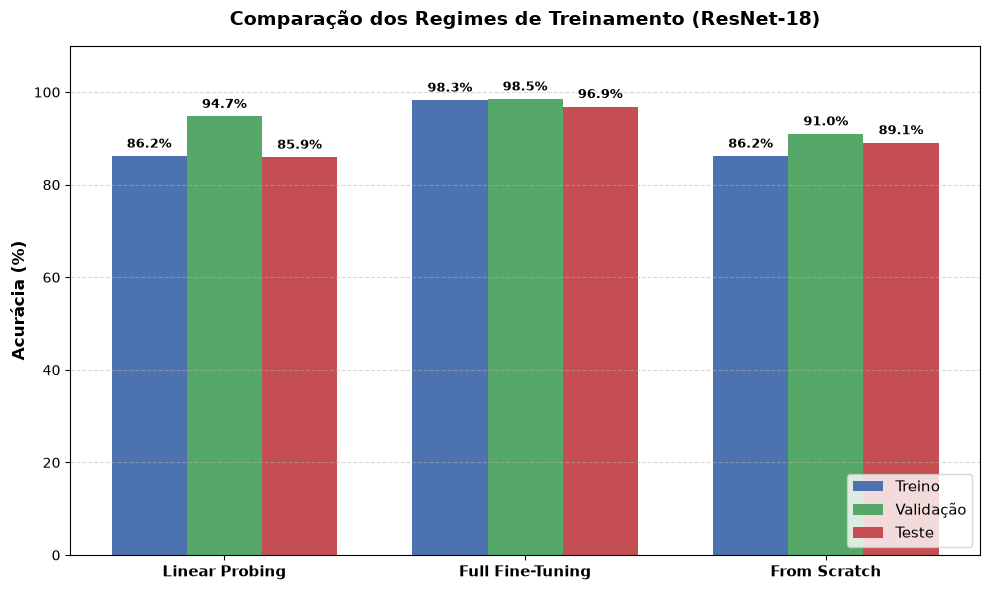

In [63]:
import json

# Supondo que você executou a avaliação de teste para os 3 modelos:
test_acc_lin_prob = evaluate(resnet_18_lin_prob, test_loader, device)[1]
test_acc_full_finet = evaluate(resnet_18_full_finet, test_loader, device)[1]
test_acc_from_scratch = evaluate(resnet_18_from_scratch, test_loader, device)[1]

# Carregando as métricas salvas dos JSONs
with open("checkpoints/beans_resnet_18_lin_prob/metrics.json") as f:
    m_lin = json.load(f)

with open("checkpoints/beans_resnet_18_full_finet/metrics.json") as f:
    m_full = json.load(f)

with open("checkpoints/beans_resnet_18_from_scratch/metrics.json") as f:
    m_scratch = json.load(f)

# Montando a estrutura para o plot
results_data = {
    "Linear Probing": {
        "train": m_lin["train_acc"],
        "val": m_lin["val_acc"],
        "test": test_acc_lin_prob
    },
    "Full Fine-Tuning": {
        "train": m_full["train_acc"],
        "val": m_full["val_acc"],
        "test": test_acc_full_finet
    },
    "From Scratch": {
        "train": m_scratch["train_acc"],
        "val": m_scratch["val_acc"],
        "test": test_acc_from_scratch
    }
}

# Gerar o gráfico
plot_regimes_comparison(results_data)